# Kesit İstatistik — İstatistiksel öğrenmenin temeli

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Ampirik risk ve genelleme

Eğitim başarısı yeni veride ne kadar korunur?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı derecelerde eğitim ve bağımsız test hatasını karşılaştır.

**Yorum sınırı:** Tek simülasyon genelleme dağılımını göstermez; test üzerinde derece seçilmez.

**Alıştırma:** Gürültüyü .3’ten .7’ye çıkar; eğitim ve test farkını açıkla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


   derece    egitim      test
0       1  0.149139  0.259512
1       2  0.143153  0.268318
2       4  0.055273  0.093369
3       8  0.051831  0.097354
4      12  0.051324  0.097734


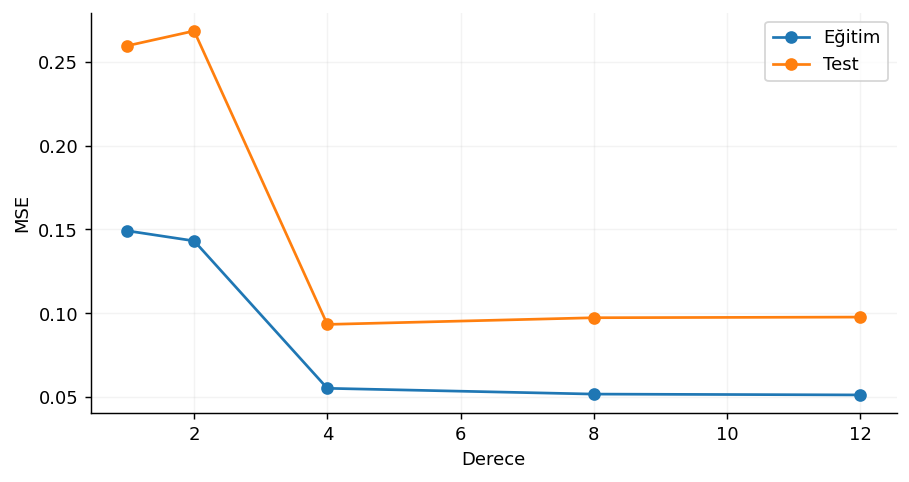

In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.uniform(-1,1,40);y=np.sin(3*x)+rng.normal(0,.3,40);xt=rng.uniform(-1,1,500);yt=np.sin(3*xt)+rng.normal(0,.3,500);rows=[]
for d in [1,2,4,8,12]:
 m=make_pipeline(PolynomialFeatures(d),Ridge(alpha=.001));m.fit(x[:,None],y);rows.append([d,mean_squared_error(y,m.predict(x[:,None])),mean_squared_error(yt,m.predict(xt[:,None]))])
t=pd.DataFrame(rows,columns=['derece','egitim','test']);print(t);plt.plot(t.derece,t.egitim,'o-',label='Eğitim');plt.plot(t.derece,t.test,'o-',label='Test');plt.xlabel('Derece');plt.ylabel('MSE');plt.legend()

## Yanlılık–varyans ve indirgenemez hata

Yanlılık ve varyansı tek eğitimden ayırabilir miyim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Aynı evrenden yeniden eğitilmiş modellerin varyansını ölç.

**Yorum sınırı:** Bileşenler gerçek f bilindiği için simülasyonda ayrılır; gerçek veride doğrudan gözlenmez.

**Alıştırma:** n=30 yerine n=100 yap; model varyansını karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


   derece  yanlilik2   varyans  gurultu
0       1   0.170889  0.025430     0.09
1       3   0.003425  0.013093     0.09
2       8   0.001112  0.089370     0.09


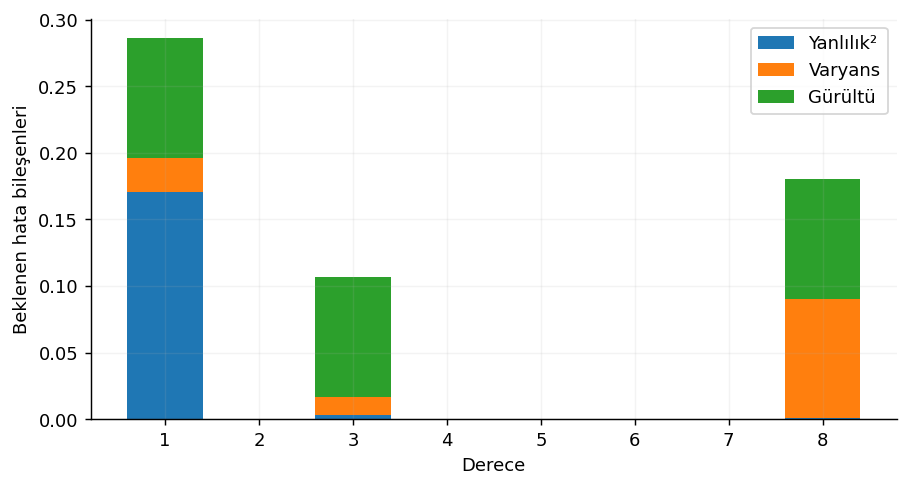

In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

grid=np.linspace(-1,1,150);truth=np.sin(3*grid);sigma=.3;rows=[]
for d in [1,3,8]:
 predictions=[]
 for repeat in range(60):
  x=rng.uniform(-1,1,30);y=np.sin(3*x)+rng.normal(0,sigma,30);m=make_pipeline(PolynomialFeatures(d),Ridge(alpha=.001));m.fit(x[:,None],y);predictions.append(m.predict(grid[:,None]))
 p=np.array(predictions);bias2=np.mean((p.mean(axis=0)-truth)**2);variance=p.var(axis=0).mean();rows.append([d,bias2,variance,sigma**2])
t=pd.DataFrame(rows,columns=['derece','yanlilik2','varyans','gurultu']);print(t);plt.bar(t.derece,t.yanlilik2,label='Yanlılık²');plt.bar(t.derece,t.varyans,bottom=t.yanlilik2,label='Varyans');plt.bar(t.derece,t.gurultu,bottom=t.yanlilik2+t.varyans,label='Gürültü');plt.xlabel('Derece');plt.ylabel('Beklenen hata bileşenleri');plt.legend()

## Bayes karar kuralı ve hata maliyeti

Kaçırma maliyeti artarsa eşik ne olmalı?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Maliyet eğrisinin minimumunu precision/recall hedefinden ayır.

**Yorum sınırı:** Teorik eşik kalibre olasılık ve sabit maliyet varsayar; burada sentetik olasılıklar üretici modelden bilinir.

**Alıştırma:** FN maliyetini 10’dan 2’ye indir; teorik ve gözlenen eşikleri karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'teorik_esik': 0.16666666666666666, 'orneklem_min': np.float64(0.19), 'min_ortalama_maliyet': np.float64(1.328)}


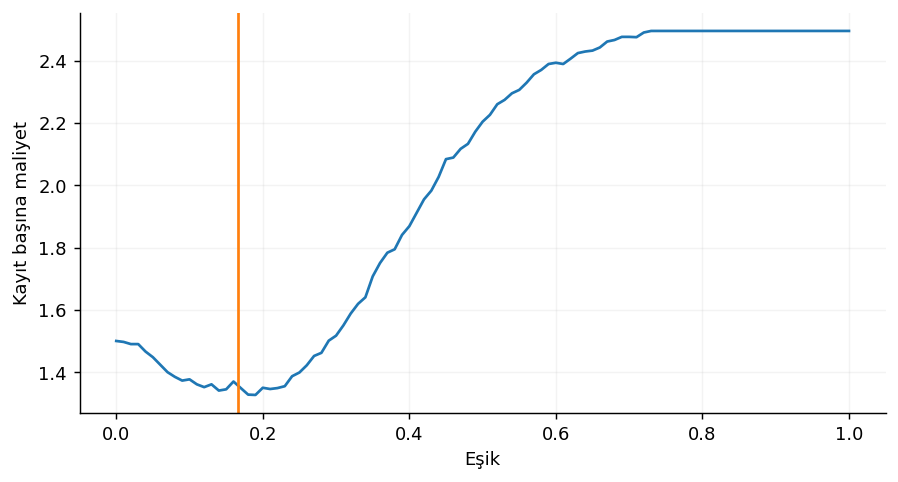

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

p=rng.beta(2,6,2000);y=rng.binomial(1,p);fp_cost,fn_cost=2,10;thresholds=np.linspace(0,1,101);cost=[]
for t in thresholds:
 pred=p>=t;cost.append((fp_cost*np.sum(pred&(y==0))+fn_cost*np.sum((~pred)&(y==1)))/len(y))
print({'teorik_esik':fp_cost/(fp_cost+fn_cost),'orneklem_min':thresholds[np.argmin(cost)],'min_ortalama_maliyet':min(cost)})
plt.plot(thresholds,cost);plt.axvline(fp_cost/(fp_cost+fn_cost),c='tab:orange');plt.xlabel('Eşik');plt.ylabel('Kayıt başına maliyet')

## Öğrenme eğrileri ve veri değeri

Daha çok veri mi daha iyi model mi gerekir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Eğitim büyüklüğüne göre tekrarlı doğrulama hatasını oku.

**Yorum sınırı:** Bağımsız test aynı kalır; simülasyon eğrisi başka evrene otomatik taşınmaz.

**Alıştırma:** Polinom derecesini 3’ten 1’e düşür; doygunlaşan hatayı yorumla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


     n  ortalama_test_MSE  tekrar_SD
0   20           0.125963   0.032189
1   40           0.099773   0.006407
2   80           0.096143   0.004347
3  160           0.091031   0.001254
4  320           0.090963   0.001034


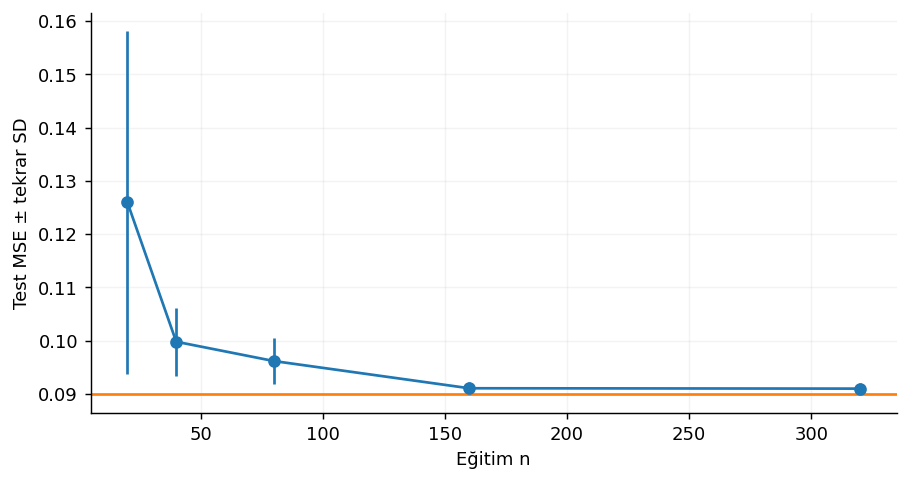

In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

xt=rng.uniform(-1,1,500);yt=np.sin(3*xt)+rng.normal(0,.3,500);sizes=[20,40,80,160,320];errors=[]
for n in sizes:
 vals=[]
 for rep in range(15):
  x=rng.uniform(-1,1,n);y=np.sin(3*x)+rng.normal(0,.3,n);m=make_pipeline(PolynomialFeatures(3),Ridge(alpha=.01));m.fit(x[:,None],y);vals.append(mean_squared_error(yt,m.predict(xt[:,None])))
 errors.append([np.mean(vals),np.std(vals)])
errors=np.array(errors);print(pd.DataFrame({'n':sizes,'ortalama_test_MSE':errors[:,0],'tekrar_SD':errors[:,1]}));plt.errorbar(sizes,errors[:,0],yerr=errors[:,1],fmt='o-');plt.axhline(.3**2,c='tab:orange');plt.xlabel('Eğitim n');plt.ylabel('Test MSE ± tekrar SD')